# **Projeto de IA - Aprendizado de Máquina**

**Grupo:**

Pedro Henrique Coelho Ponte

Yago Lobo Ximenes

Renan Ferreira Rodrigues

## **O conjunto de dados**

### Origem e domínio

O **mfeat-fourier** é uma das seis *views* do **Multiple Features Dataset (mfeat)**, doado por Robert P. W. Duin (Department of Applied Physics, Delft University of Technology) ao UCI Machine Learning Repository.

Os dados são **numerais manuscritos (0–9) extraídos de uma coleção de mapas de serviços públicos holandeses**, digitalizados em imagens binárias. As imagens originais **foram perdidas**; segundo a documentação, versões amostradas em 15 × 16 pixels ainda podem ser obtidas a partir da view `mfeat-pix`, recurso que utilizaremos na análise de erros para visualizar os casos mal classificados.

### Um conjunto multi-view

Os mesmos 2 000 caracteres foram descritos por seis conjuntos de atributos distintos:

| View | Atributos | Descrição |
|---|---|---|
| `mfeat-fou` | **76** | Coeficientes de Fourier do contorno — **utilizada neste trabalho** |
| `mfeat-fac` | 216 | Correlações de perfil |
| `mfeat-kar` | 64 | Coeficientes de Karhunen-Loève |
| `mfeat-pix` | 240 | Médias de pixel em janelas 2 × 3 |
| `mfeat-zer` | 47 | Momentos de Zernike |
| `mfeat-mor` | 6 | Atributos morfológicos |

Este trabalho utiliza **apenas a view `fou`**, reportada na literatura como uma das mais fracas quando tomada isoladamente e estudaremos o porquê disso. Ela busca prever o dígito representado utilizando 76 atributos no total.

### O que são os 76 atributos

São **descritores de Fourier do contorno** do caractere. A leitura padrão na literatura de descritores de forma é que se trata das **magnitudes** dos coeficientes da transformada de Fourier discreta do contorno, normalizadas em escala e com a fase descartada, o que confere invariância a translação, escala, rotação e ponto inicial do traçado. Os valores observados no arquivo (todos não-negativos e limitados a um intervalo estreito) são coerentes com essa interpretação.

A principal consequência dessa invariância é a **impossibilidade, em princípio, de distinguir formas que sejam rotações uma da outra**, ou seja, os dígitos "6" e "9" podem causar ambiguidade forte. Essa hipótese é desenvolvida e testada empiricamente na seção de análise dos erros.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.io.arff import loadarff

ARFF_PATH = Path("dataset_14_mfeat-fourier.arff")

# loadarff devolve (structured ndarray, MetaData).
raw, meta = loadarff(ARFF_PATH)
df = pd.DataFrame(raw)

# A classe 1 representa o digito 0 e assim por diante, logo faz-se a transformação de classe para digito.
df["class"] = df["class"].str.decode("utf-8").astype(int)
df["digit"] = df["class"] - 1

FEATURES = [c for c in df.columns if c.startswith("att")]

X = df[FEATURES].astype(np.float64)
y = df["digit"]  # 0..9, o dígito de fato representado

print(f"X: {X.shape}   y: {y.shape}")
print(f"Atributos: {FEATURES[0]} ... {FEATURES[-1]}")
print(f"Tipos distintos em X: {sorted(set(X.dtypes.astype(str)))}")
print(f"Rótulos brutos no arquivo: {sorted(df['class'].unique().tolist())}")
print(f"Dígitos após a conversão:  {sorted(y.unique().tolist())}")

X: (2000, 76)   y: (2000,)
Atributos: att1 ... att76
Tipos distintos em X: ['float64']
Rótulos brutos no arquivo: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Dígitos após a conversão:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [16]:
# Características descritivas, todas calculadas a partir dos dados carregados.
n_inst, n_attr = X.shape
n_classes = y.nunique()
contagem = y.value_counts().sort_index()

n_faltantes = int(X.isna().sum().sum())
n_duplicatas = int(X.duplicated().sum())

desvios = X.std()
minimos, maximos = X.min(), X.max()

print(f"Instâncias .................. {n_inst}")
print(f"Atributos preditivos ........ {n_attr}, Tipos de dados: {X.dtypes.value_counts().to_dict()}")
print(f"Classes ..................... {n_classes}")
print(f"Valores faltantes ........... {n_faltantes}")
print(f"Linhas duplicadas ........... {n_duplicatas}")
print(f"Faixa global dos valores .... [{minimos.min():.4f}, {maximos.max():.4f}]")
print(f"Desvio-padrão por atributo .. {desvios.min():.4f} ({desvios.idxmin()}) a "f"{desvios.max():.4f} ({desvios.idxmax()})")
print(f"Instâncias por atributo ..... {n_inst / n_attr:.1f}")

# Checagem se duplicatas produzem mesma classe.
dup = X.duplicated(keep=False)
if dup.any():
    chave = pd.Series(list(map(tuple, X[dup].to_numpy())), index=X.index[dup])
    rotulos_por_grupo = df.loc[dup, "digit"].groupby(chave).nunique()
    print(
        f"\nGrupos de linhas idênticas .. {len(rotulos_por_grupo)} "
        f"| com rótulos divergentes: {int((rotulos_por_grupo > 1).sum())}"
    )

print("\nInstâncias por dígito:")
print(contagem.to_string())

Instâncias .................. 2000
Atributos preditivos ........ 76, Tipos de dados: {dtype('float64'): 76}
Classes ..................... 10
Valores faltantes ........... 0
Linhas duplicadas ........... 6
Faixa global dos valores .... [0.0002, 0.7965]
Desvio-padrão por atributo .. 0.0376 (att46) a 0.1762 (att2)
Instâncias por atributo ..... 26.3

Grupos de linhas idênticas .. 6 | com rótulos divergentes: 0

Instâncias por dígito:
digit
0    200
1    200
2    200
3    200
4    200
5    200
6    200
7    200
8    200
9    200


### Discussão das características

**Balanceamento.** O conjunto é perfeitamente balanceado: exatamente 200 instâncias por dígito. Ainda assim reportaremos F1-macro e a matriz de confusão, além da acurácia, porque o interesse não é apenas o acerto global, mas onde os erros se concentram.

**Qualidade.** Não há valores faltantes, o que elimina toda a etapa de imputação. Existem 6 pares de linhas exatamente duplicadas, e verificamos que **todos têm rótulos concordantes**, não há, portanto, ruído de rótulo por essa via. A decisão de removê-las ou mantê-las é discutida na seção de pré-processamentos.

**Ordenação do arquivo.** As instâncias estão dispostas em **blocos contíguos por classe** (as 200 primeiras são o dígito 0, as 200 seguintes o dígito 1, e assim por diante). Todas as validações cruzadas deste trabalho usam, por isso, embaralhamento das instâncias.

**Rótulos deslocados.** O atributo alvo é declarado no arquivo como nominal com valores `1..10`, e não `0..9`. Combinado com a ordenação acima, o mapeamento correto é **classe *k* = dígito *k*−1**. Fazemos essa conversão já na carga, para que matrizes de confusão e discussões se refiram ao dígito de fato representado.

**Dimensionalidade.** São 76 atributos para 2 000 instâncias, razão global de ~26 amostras por atributo. Na verdade, a leitura mais relevante é por classe: 200 instâncias ÷ 76 atributos ≈ 2,6, bem abaixo da regra de bolso de ao menos 10 amostras por atributo por classe. Não se trata de um caso extremo de alta dimensionalidade, mas é apertado o suficiente para prever dificuldade em modelos com muitos parâmetros a estimar. Resta saber se a dimensionalidade *efetiva* é menor que 76 — ou seja, se os atributos são redundantes entre si a ponto de permitir compressão. Trata-se de uma hipótese a ser verificada, e a análise exploratória a seguir a testa diretamente.

**Escala.** Todos os atributos são contínuos, não-negativos e de magnitude comparável, mas não idêntica: os desvios-padrão variam por um fator de ~4,7. Como a distância euclidiana soma *quadrados*, o atributo de maior dispersão acaba pesando cerca de 22 vezes mais que o de menor em qualquer decisão baseada em distância, sem ser mais informativo por isso. A padronização é, portanto, necessária, e sua implementação é detalhada na seção de pré-processamentos.

## **Análise exploratória dos dados**

#### Paleta de cores

In [17]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.preprocessing import StandardScaler

# Sistema visual único para todas as figuras da seção. As figuras do notebook são
# imagens estáticas, então apenas o modo claro se aplica.
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"
AZUL, LARANJA, VERMELHO = "#2a78d6", "#eb6834", "#e34948"
NEUTRO, FUNDO_PONTO = "#f0efec", "#d6d5cf"

# Sequencial: um único matiz, claro -> escuro (magnitude).
RAMPA_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_azul", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])
# Divergente: dois matizes opostos com cinza neutro no meio (polaridade em torno de 0).
RAMPA_DIV = mpl.colors.LinearSegmentedColormap.from_list(
    "div_azul_vermelho", [AZUL, "#9ec5f4", NEUTRO, "#f0a3a2", VERMELHO])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.grid": True, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110,
})


#### Padronização dos dados
Sem ela, as análises seriam enviesadas por atributos com maior dispersão.

In [18]:
Z = StandardScaler().fit_transform(X.to_numpy())
yv = y.to_numpy()

print(f"Z: {Z.shape} | média {Z.mean():+.1e} | desvio {Z.std():.3f}")

Z: (2000, 76) | média -1.7e-17 | desvio 1.000


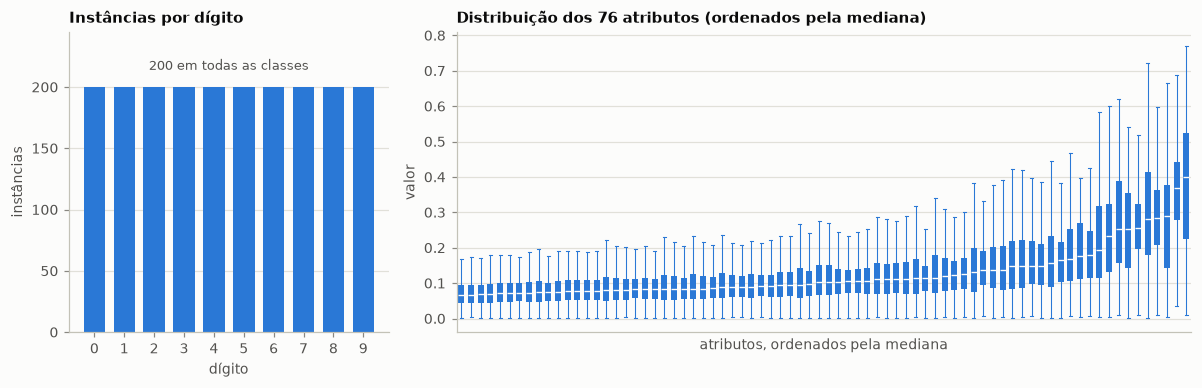

Assimetria por atributo: mediana 0.55 | máx 1.03 | 1 de 76 acima de 1
Outliers (1,5·IQR): 1.00% das células
  instâncias com >=1 atributo sinalizado: 660 (esperado ao acaso ~1068)
  instâncias com >=10 atributos sinalizados: 2


In [19]:
from scipy.stats import skew

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.3]})

ax1.bar(contagem.index, contagem.values, color=AZUL, width=0.72)
ax1.set_title("Instâncias por dígito", loc="left", fontsize=10, weight="bold")
ax1.set(xlabel="dígito", ylabel="instâncias", xticks=range(10), ylim=(0, 245))
ax1.grid(axis="x", visible=False)
ax1.annotate("200 em todas as classes", xy=(4.5, 214), ha="center", fontsize=8.5, color=INK2)

ordem = X.median().sort_values().index
ax2.boxplot(
    [X[c] for c in ordem], widths=0.62, showfliers=False, patch_artist=True,
    medianprops=dict(color=SURFACE, linewidth=0.9),
    whiskerprops=dict(color=AZUL, linewidth=0.7),
    capprops=dict(color=AZUL, linewidth=0.7),
    boxprops=dict(facecolor=AZUL, edgecolor="none"),
)
ax2.set_title("Distribuição dos 76 atributos (ordenados pela mediana)",
              loc="left", fontsize=10, weight="bold")
ax2.set(xlabel="atributos, ordenados pela mediana", ylabel="valor", xticks=[])
ax2.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

s = skew(X.to_numpy(), axis=0)
q1, q3 = np.percentile(X.to_numpy(), [25, 75], axis=0)
iqr = q3 - q1
fora = (X.to_numpy() < q1 - 1.5 * iqr) | (X.to_numpy() > q3 + 1.5 * iqr)
esperado = n_inst * (1 - 0.99 ** n_attr)

print(f"Assimetria por atributo: mediana {np.median(s):.2f} | máx {s.max():.2f} "
      f"| {(s > 1).sum()} de {n_attr} acima de 1")
print(f"Outliers (1,5·IQR): {100 * fora.mean():.2f}% das células")
print(f"  instâncias com >=1 atributo sinalizado: {(fora.sum(1) > 0).sum()} "
      f"(esperado ao acaso ~{esperado:.0f})")
print(f"  instâncias com >=10 atributos sinalizados: {(fora.sum(1) >= 10).sum()}")

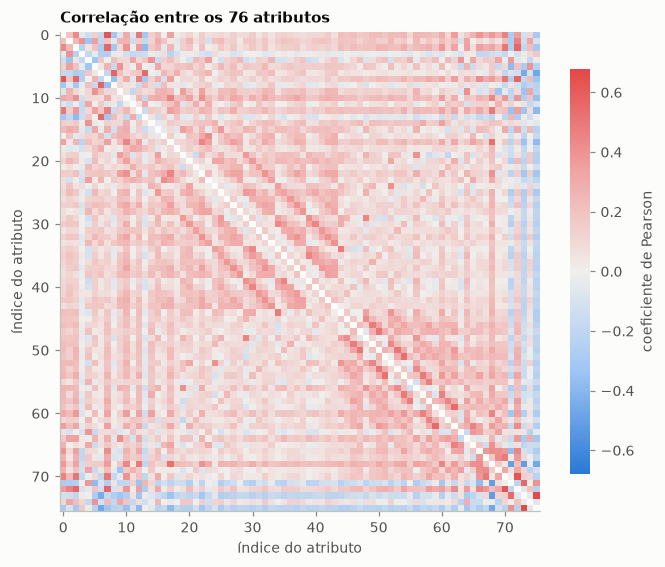

|corr| média (todos os 2850 pares): 0.146 | mediana 0.127
|corr| média entre adjacentes (k, k+1): 0.135
|corr| máxima: 0.679


In [20]:
Corr = np.corrcoef(Z.T)
fora_diag = Corr[np.triu_indices(n_attr, 1)]
lim = np.abs(fora_diag).max()

# A diagonal (sempre 1,0) é mascarada para não degradar a escala.
Cm = Corr.copy()
np.fill_diagonal(Cm, np.nan)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
cmap = RAMPA_DIV.copy()
cmap.set_bad(SURFACE)
im = ax.imshow(Cm, cmap=cmap, vmin=-lim, vmax=lim)  # escala simétrica em torno de 0
ax.set_title("Correlação entre os 76 atributos", loc="left", fontsize=10, weight="bold")
ax.set(xlabel="índice do atributo", ylabel="índice do atributo")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.82)
cb.set_label("coeficiente de Pearson", color=INK2)
cb.outline.set_visible(False)

plt.tight_layout()
plt.show()

adj = np.array([Corr[i, i + 1] for i in range(n_attr - 1)])
print(f"|corr| média (todos os {len(fora_diag)} pares): {np.abs(fora_diag).mean():.3f} "
      f"| mediana {np.median(np.abs(fora_diag)):.3f}")
print(f"|corr| média entre adjacentes (k, k+1): {np.abs(adj).mean():.3f}")
print(f"|corr| máxima: {np.abs(fora_diag).max():.3f}")

#### Componentes principais
Quantos eixos ortogonais são precisos para reter a variação dos 76 atributos.

In [21]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(Z)
vr = pca_full.explained_variance_ratio_
cum = np.cumsum(vr)
k90, k95 = np.searchsorted(cum, 0.90) + 1, np.searchsorted(cum, 0.95) + 1
pr = pca_full.explained_variance_.sum() ** 2 / (pca_full.explained_variance_ ** 2).sum()

print("Componentes necessários por limiar de variância:")
for t in (0.5, 0.8, 0.9, 0.95, 0.99):
    print(f"  {t:.0%} -> {np.searchsorted(cum, t) + 1:2d} de {n_attr}")
print(f"\nPC1..PC5: {np.round(vr[:5] * 100, 1)} %  (soma {vr[:5].sum():.1%})")
print(f"Dimensão efetiva (participation ratio): {pr:.1f}")

Componentes necessários por limiar de variância:
  50% -> 11 de 76
  80% -> 33 de 76
  90% -> 47 de 76
  95% -> 58 de 76
  99% -> 71 de 76

PC1..PC5: [15.6  6.8  6.2  3.6  3.3] %  (soma 35.7%)
Dimensão efetiva (participation ratio): 22.4


#### A correlação é só linear
Pearson mede associação linear; Spearman, monotônica. Ambas dão ~zero para uma relação em arco.
A **correlação de distância (dCor)** vale zero *se e somente se* há independência, então capta
dependência de qualquer formato. Como ela é enviesada para cima em amostra finita, a referência
é um nulo por permutação — embaralhar cada coluna destrói a dependência e preserva as marginais.

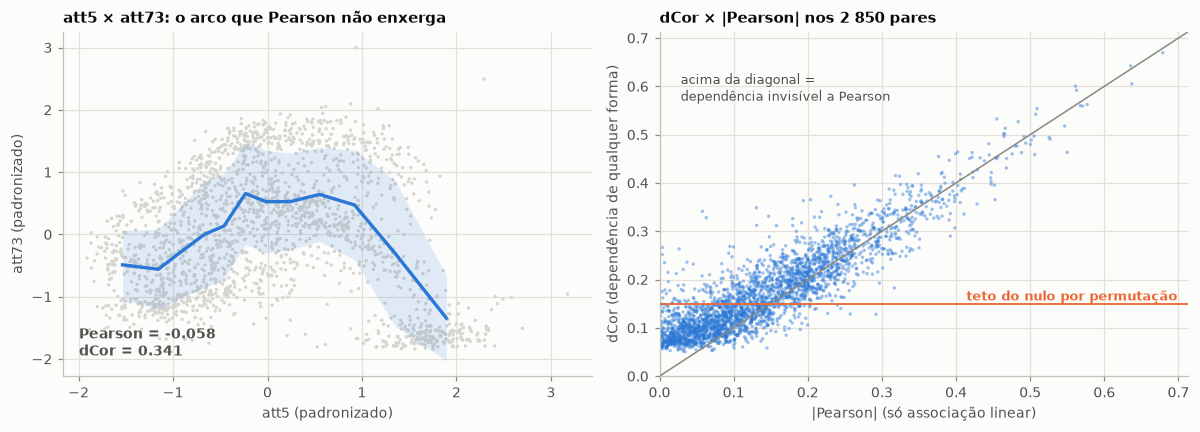

|Pearson |: média 0.146 | máx 0.679
|Spearman|: média 0.140 | máx 0.652  -> sem não linearidade monotônica

dCor           : média 0.175 | máx 0.670
dCor sob o nulo: média 0.075 | máx 0.150
pares acima do teto do nulo: 1470 de 2850
entre os 2083 pares com |Pearson|<0,2, dCor máx = 0.363

Excesso sobre o nulo, ambos com n=200 — global +0.079 | dentro da classe +0.084
  -> iguais: a dependência é dos atributos, não da mistura de classes


In [22]:
from scipy.stats import spearmanr

rng = np.random.default_rng(0)


def _dist_centrada(v):
    A = np.abs(v[:, None] - v[None, :])
    return A - A.mean(0, keepdims=True) - A.mean(1, keepdims=True) + A.mean()


def dcor_matriz(M):
    """dCor entre todas as colunas de M. Empilhar as matrizes duplo-centradas e fazer um
    único produto Ac @ Ac.T troca 2850 laços por uma multiplicação de matrizes."""
    n, p = M.shape
    Ac = np.stack([_dist_centrada(M[:, j]).ravel() for j in range(p)])
    dcov2 = (Ac @ Ac.T) / (n * n)
    d = np.sqrt(np.maximum(np.diag(dcov2), 1e-300))
    return np.sqrt(np.maximum(dcov2, 0)) / np.sqrt(np.outer(d, d))


iu = np.triu_indices(n_attr, 1)
amostra = rng.choice(n_inst, 500, replace=False)
dcor = dcor_matriz(Z[amostra])[iu]
Zperm = np.column_stack([rng.permutation(Z[amostra][:, j]) for j in range(n_attr)])
dcor_nulo = dcor_matriz(Zperm)[iu]
teto_nulo = dcor_nulo.max()

pearson_abs = np.abs(Corr[iu])
spear = np.abs(spearmanr(Z).statistic[iu])

A, B = 5, 73  # par com a maior dependência não linear encontrada
xa, ya = Z[:, A - 1], Z[:, B - 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.0))

ax1.scatter(xa, ya, s=5, c=FUNDO_PONTO, edgecolors="none", zorder=1)
bordas = np.quantile(xa, np.linspace(0, 1, 13))
cx, cm, cs = [], [], []
for i in range(12):
    m = (xa >= bordas[i]) & (xa <= bordas[i + 1])
    cx.append(xa[m].mean()); cm.append(ya[m].mean()); cs.append(ya[m].std())
cx, cm, cs = map(np.array, (cx, cm, cs))
ax1.fill_between(cx, cm - cs, cm + cs, color=AZUL, alpha=0.13, zorder=2, linewidth=0)
ax1.plot(cx, cm, color=AZUL, linewidth=2.2, zorder=3)
r_ab = np.corrcoef(xa, ya)[0, 1]
d_ab = dcor_matriz(Z[amostra][:, [A - 1, B - 1]])[0, 1]
ax1.set_title(f"att{A} × att{B}: o arco que Pearson não enxerga",
              loc="left", fontsize=10, weight="bold")
ax1.set(xlabel=f"att{A} (padronizado)", ylabel=f"att{B} (padronizado)")
ax1.annotate(f"Pearson = {r_ab:+.3f}\ndCor = {d_ab:.3f}", xy=(0.03, 0.06),
             xycoords="axes fraction", fontsize=9, color=INK2, weight="bold")

ax2.scatter(pearson_abs, dcor, s=5, c=AZUL, edgecolors="none", alpha=0.45, zorder=2)
lim = max(pearson_abs.max(), dcor.max()) * 1.05
ax2.plot([0, lim], [0, lim], color=MUTED, linewidth=1, zorder=3)
ax2.axhline(teto_nulo, color=LARANJA, linewidth=1.2, zorder=3)
ax2.annotate("teto do nulo por permutação", xy=(lim * 0.98, teto_nulo), ha="right",
             va="bottom", fontsize=8.5, color=LARANJA, weight="bold")
ax2.annotate("acima da diagonal =\ndependência invisível a Pearson",
             xy=(0.04, 0.80), xycoords="axes fraction", fontsize=8.5, color=INK2)
ax2.set_title("dCor × |Pearson| nos 2 850 pares", loc="left", fontsize=10, weight="bold")
ax2.set(xlabel="|Pearson| (só associação linear)",
        ylabel="dCor (dependência de qualquer forma)", xlim=(0, lim), ylim=(0, lim))

plt.tight_layout()
plt.show()

print(f"|Pearson |: média {pearson_abs.mean():.3f} | máx {pearson_abs.max():.3f}")
print(f"|Spearman|: média {spear.mean():.3f} | máx {spear.max():.3f}"
      f"  -> sem não linearidade monotônica")
print(f"\ndCor           : média {dcor.mean():.3f} | máx {dcor.max():.3f}")
print(f"dCor sob o nulo: média {dcor_nulo.mean():.3f} | máx {teto_nulo:.3f}")
print(f"pares acima do teto do nulo: {(dcor > teto_nulo).sum()} de {len(dcor)}")
fraco = pearson_abs < 0.2
print(f"entre os {fraco.sum()} pares com |Pearson|<0,2, dCor máx = {dcor[fraco].max():.3f}")

# Controle: a mistura de 10 classes poderia fabricar dependência aparente entre atributos.
# O viés do nulo depende de n, então o global é reamostrado com os mesmos 200 pontos por
# grupo — comparar n=500 com n=200 invalidaria a comparação.
def excesso(M):
    Mp = np.column_stack([rng.permutation(M[:, j]) for j in range(n_attr)])
    return dcor_matriz(M)[iu].mean() - dcor_matriz(Mp)[iu].mean()


exc_global = excesso(Z[rng.choice(n_inst, 200, replace=False)])
exc_classe = [excesso(Z[yv == k]) for k in range(10)]
print(f"\nExcesso sobre o nulo, ambos com n=200 — global {exc_global:+.3f} | "
      f"dentro da classe {np.mean(exc_classe):+.3f}")
print("  -> iguais: a dependência é dos atributos, não da mistura de classes")

#### Dimensão intrínseca: os dados são curvos
Se há dependência não linear, a dimensão em que os dados realmente vivem deve ficar bem abaixo dos
componentes que o PCA exige. Estimadores de dimensão intrínseca medem isso sem supor linearidade,
mas subestimam em dimensão alta — por isso o primeiro painel **calibra o estimador** em dados de
dimensão conhecida antes de interpretar qualquer valor. O controle decisivo é uma gaussiana de
*mesma matriz de covariância*: ela tem toda a estrutura linear dos dados reais e nenhuma curvatura.

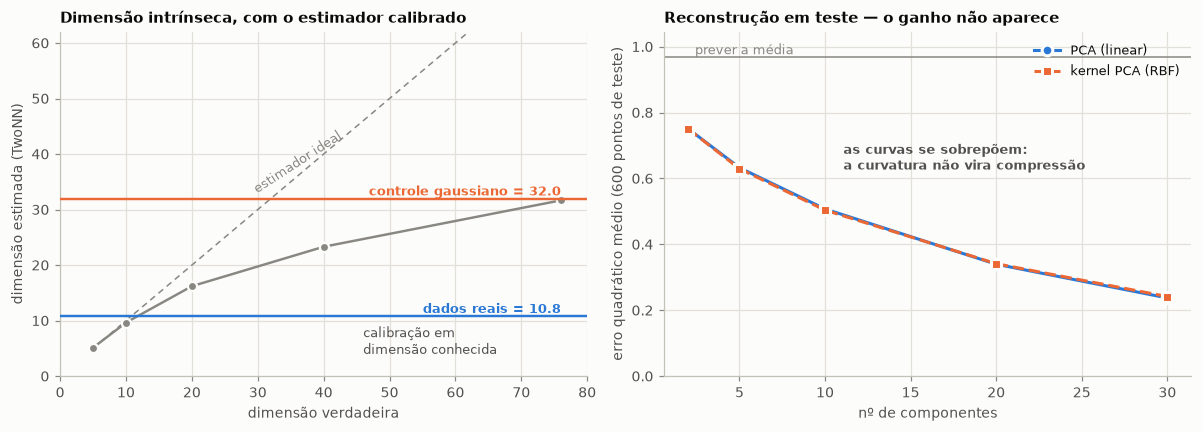

Calibração do TwoNN (verdadeira -> estimada): 5->5.1 | 10->9.6 | 20->16.2 | 40->23.3 | 76->31.7

Dados reais ............................. TwoNN 10.8 | MLE 8.9
  sem duplicatas exatas ................. TwoNN 10.9 | MLE 10.2
  dentro de cada classe (média das 10) .. TwoNN 11.1
  controle gaussiano .................... TwoNN 32.0 | MLE 28.5
  PCA linear para 95% da variância ...... 58 componentes
  robustez ao corte de cauda: 0.80->11.0 | 0.90->10.8 | 0.95->10.6

Reconstrução em teste (menor é melhor):
  k= 2 | PCA 0.7509 | kPCA 0.7503 | ganho  +0.1%
  k= 5 | PCA 0.6326 | kPCA 0.6295 | ganho  +0.5%
  k=10 | PCA 0.5074 | kPCA 0.5038 | ganho  +0.7%
  k=20 | PCA 0.3396 | kPCA 0.3413 | ganho  -0.5%
  k=30 | PCA 0.2373 | kPCA 0.2416 | ganho  -1.8%

Preliminar — acurácia 10-fold, sem ajuste de hiperparâmetros:
  LogReg (linear)  0.818 ± 0.018
  SVM linear       0.819 ± 0.027
  kNN k=5          0.803 ± 0.027
  SVM RBF          0.830 ± 0.021
  Random Forest    0.828 ± 0.022


In [23]:
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.decomposition import KernelPCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


def twonn(M, frac=0.9):
    """Dimensão intrínseca por TwoNN (Facco et al., 2017): razão entre as distâncias ao
    1º e ao 2º vizinho mais próximo. Não supõe linearidade."""
    d, _ = NearestNeighbors(n_neighbors=3).fit(M).kneighbors(M)
    r1, r2 = d[:, 1], d[:, 2]
    ok = r1 > 0
    mu = np.sort(r2[ok] / r1[ok])
    N = len(mu); k = int(N * frac)
    x = np.log(mu[:k])
    return float((x @ -np.log(1 - np.arange(1, k + 1) / N)) / (x @ x))


def mle_id(M, k=10):
    """MLE de Levina-Bickel — segundo estimador, para checagem cruzada."""
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(M).kneighbors(M)
    d = np.maximum(d[:, 1:], 1e-12)
    return float(1 / np.mean((np.log(d[:, [-1]]) - np.log(d[:, :-1])).mean(1)))


# Geradores próprios: assim a calibração e o controle não dependem de quanto do `rng`
# as células anteriores consumiram, e os valores citados no texto ficam estáveis.
rng_cal, rng_ctl = np.random.default_rng(1), np.random.default_rng(2)

d_verd = [5, 10, 20, 40, 76]
d_est = [twonn(StandardScaler().fit_transform(
    rng_cal.normal(size=(n_inst, dv)) @ rng_cal.normal(size=(dv, n_attr)))) for dv in d_verd]

id_real, id_real_mle = twonn(Z), mle_id(Z)
Zsem = StandardScaler().fit_transform(X.drop_duplicates().to_numpy())
Zgauss = rng_ctl.multivariate_normal(np.zeros(n_attr), np.cov(Z.T), size=n_inst)
id_gauss = twonn(Zgauss)

# O kernel PCA reconstrói melhor que o PCA? Teste em conjunto separado, para que o
# regressor de pré-imagem do kPCA não possa decorar os pontos.
Xtr, Xte = train_test_split(X.to_numpy(), test_size=600, random_state=0)
sc = StandardScaler().fit(Xtr)
Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
ks = [2, 5, 10, 20, 30]
err_pca, err_kpca = [], []
for k in ks:
    p = PCA(k).fit(Ztr)
    err_pca.append(((Zte - p.inverse_transform(p.transform(Zte))) ** 2).mean())
    err_kpca.append(min(
        ((Zte - kp.inverse_transform(kp.transform(Zte))) ** 2).mean()
        for kp in [KernelPCA(n_components=k, kernel="rbf", gamma=g, alpha=1e-3,
                             fit_inverse_transform=True, random_state=0).fit(Ztr)
                   for g in (0.002, 0.005, 0.01)]))
base_rec = (Zte ** 2).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.0))

ax1.plot(d_verd, d_verd, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax1.annotate("estimador ideal", xy=(29, 33), fontsize=8.5, color=MUTED, rotation=33)
ax1.plot(d_verd, d_est, "o-", color=MUTED, linewidth=1.6, markersize=6,
         markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
ax1.annotate("calibração em\ndimensão conhecida", xy=(40, d_est[3]), xytext=(46, 4),
             fontsize=8.5, color=INK2)
for val, cor, rot in [(id_real, AZUL, f"dados reais = {id_real:.1f}"),
                      (id_gauss, LARANJA, f"controle gaussiano = {id_gauss:.1f}")]:
    ax1.axhline(val, color=cor, linewidth=1.6, zorder=4)
    ax1.annotate(rot, xy=(76, val), ha="right", va="bottom", fontsize=8.5,
                 color=cor, weight="bold")
ax1.set_title("Dimensão intrínseca, com o estimador calibrado", loc="left",
              fontsize=10, weight="bold")
ax1.set(xlabel="dimensão verdadeira", ylabel="dimensão estimada (TwoNN)",
        xlim=(0, 80), ylim=(0, 62))

ax2.axhline(base_rec, color=MUTED, linewidth=1, zorder=1)
ax2.annotate("prever a média", xy=(2.4, base_rec), ha="left", va="bottom",
             fontsize=8.5, color=MUTED)
ax2.plot(ks, err_pca, "o-", color=AZUL, linewidth=2, markersize=7,
         markeredgecolor=SURFACE, markeredgewidth=2, label="PCA (linear)", zorder=3)
ax2.plot(ks, err_kpca, "s--", color=LARANJA, linewidth=2, markersize=6,
         markeredgecolor=SURFACE, markeredgewidth=2, label="kernel PCA (RBF)", zorder=4)
ax2.legend(loc="upper right", fontsize=8.5)
ax2.annotate("as curvas se sobrepõem:\na curvatura não vira compressão",
             xy=(0.34, 0.60), xycoords="axes fraction", fontsize=8.5,
             color=INK2, weight="bold")
ax2.set_title("Reconstrução em teste — o ganho não aparece", loc="left",
              fontsize=10, weight="bold")
ax2.set(xlabel="nº de componentes", ylabel="erro quadrático médio (600 pontos de teste)",
        ylim=(0, base_rec * 1.08))

plt.tight_layout()
plt.show()

print("Calibração do TwoNN (verdadeira -> estimada): "
      + " | ".join(f"{a}->{b:.1f}" for a, b in zip(d_verd, d_est)))
print(f"\nDados reais ............................. TwoNN {id_real:.1f} | MLE {id_real_mle:.1f}")
print(f"  sem duplicatas exatas ................. TwoNN {twonn(Zsem):.1f} | MLE {mle_id(Zsem):.1f}")
print(f"  dentro de cada classe (média das 10) .. TwoNN "
      f"{np.mean([twonn(Z[yv == k]) for k in range(10)]):.1f}")
print(f"  controle gaussiano .................... TwoNN {id_gauss:.1f} | MLE {mle_id(Zgauss):.1f}")
print(f"  PCA linear para 95% da variância ...... {k95} componentes")
print("  robustez ao corte de cauda: "
      + " | ".join(f"{f:.2f}->{twonn(Z, f):.1f}" for f in (0.80, 0.90, 0.95)))

print("\nReconstrução em teste (menor é melhor):")
for k, ep, ek in zip(ks, err_pca, err_kpca):
    print(f"  k={k:2d} | PCA {ep:.4f} | kPCA {ek:.4f} | ganho {100 * (ep - ek) / ep:+5.1f}%")

# Verificação preliminar; a avaliação rigorosa, com CV aninhada, é da seção do pipeline.
print("\nPreliminar — acurácia 10-fold, sem ajuste de hiperparâmetros:")
cv10 = StratifiedKFold(10, shuffle=True, random_state=0)
for nome, clf in [("LogReg (linear)", LogisticRegression(max_iter=3000)),
                  ("SVM linear", SVC(kernel="linear")),
                  ("kNN k=5", KNeighborsClassifier(5)),
                  ("SVM RBF", SVC(kernel="rbf")),
                  ("Random Forest", RandomForestClassifier(400, random_state=0, n_jobs=-1))]:
    s = cross_val_score(make_pipeline(StandardScaler(), clf), X.to_numpy(), yv,
                        cv=cv10, n_jobs=-1)
    print(f"  {nome:16s} {s.mean():.3f} ± {s.std():.3f}")

**O que estes dois blocos estabelecem.**

1. **Existe dependência não linear**, e Pearson é cego a ela. O par `att5`×`att73` desenha um arco
   com Pearson de −0,06; 1 470 dos 2 850 pares ficam acima do teto do nulo. O controle intraclasse
   mostra que a dependência é dos atributos, não da mistura de dígitos.
2. **A geometria é curva.** O TwoNN mede 10,8 nos dados reais contra 32,0 no controle gaussiano de
   mesma covariância — e 10,8 cai na faixa em que a calibração mostra o estimador confiável. O MLE
   concorda. A lacuna entre ~11 e os 58 componentes do PCA **é** a curvatura: o PCA só ajusta
   subespaços planos e gasta dimensões acompanhando o giro do espaço tangente.
3. **Mas a curvatura não é explorável.** O kernel PCA não reconstrói melhor que o PCA — ganha 0,7%
   no melhor caso e chega a perder 1,8%. O SVM-RBF supera a regressão logística em 1,2 ponto, dentro
   de um desvio-padrão, e o kNN fica *abaixo* do modelo linear.

A conciliação: dimensão intrínseca é uma medida **local**, o PCA é **global e linear**. O espaço
tangente gira, mas gira suave o bastante para que aproximações lineares quase não percam nada.
Isso explica por que o t-SNE — não linear e local — exibe estrutura mais limpa que o PCA sem que
isso vire vantagem preditiva.

*Ressalva:* o teste cobre "kPCA-RBF com pré-imagem por ridge", não todo método não linear.

**Consequência:** o teto de desempenho deve ficar em torno de 83%, e trocar de família de modelo
move pouco. Isso é mais uma evidência de que o limite vem da **representação de Fourier**, não do
classificador — o que desloca o interesse para *onde* todos erram.

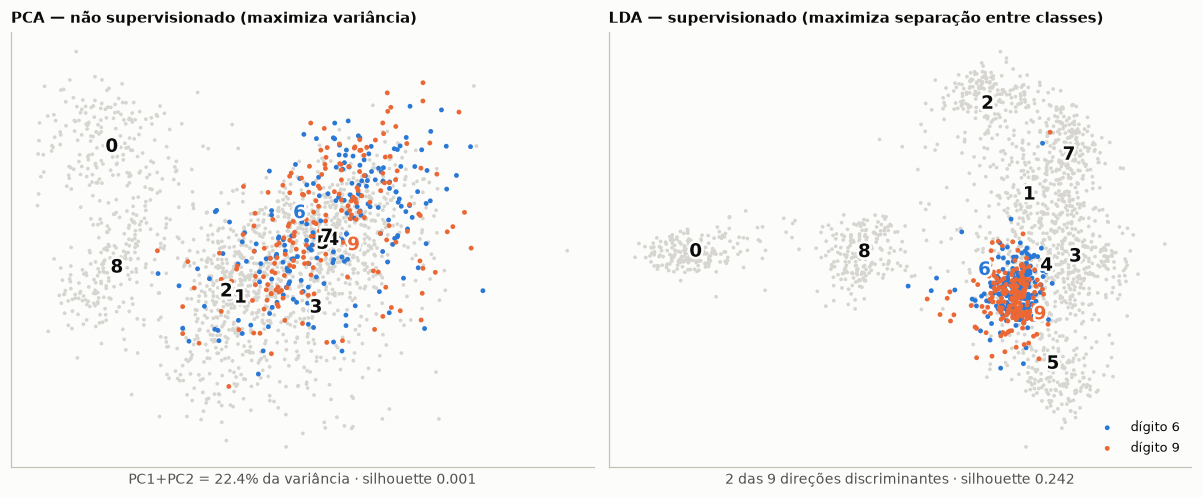

Silhouette com os rótulos VERDADEIROS:
  espaço original 76D : 0.038
  projeção PCA 2D     : 0.001
  projeção LDA 2D     : 0.242


In [24]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score

DESTAQUE = {6: AZUL, 9: LARANJA}


def scatter_digitos(ax, P, titulo, sub):
    outros = ~np.isin(yv, list(DESTAQUE))
    ax.scatter(P[outros, 0], P[outros, 1], s=6, c=FUNDO_PONTO, edgecolors="none", zorder=1)
    for d, cor in DESTAQUE.items():
        m = yv == d
        ax.scatter(P[m, 0], P[m, 1], s=10, c=cor, edgecolors="none", zorder=3,
                   label=f"dígito {d}")

    # Os centroides de 6 e 9 quase coincidem — que é justamente o achado. Os dois
    # numerais são afastados em sentidos opostos para continuarem legíveis.
    dx = 0.055 * np.ptp(P[:, 0])
    desloc = {6: (-dx, 0.55 * dx), 9: (dx, -0.55 * dx)}
    for d in range(10):
        cx, cy = P[yv == d].mean(0)
        ox, oy = desloc.get(d, (0.0, 0.0))
        ax.text(cx + ox, cy + oy, str(d), fontsize=12, weight="bold",
                ha="center", va="center", color=DESTAQUE.get(d, INK), zorder=4,
                path_effects=[pe.withStroke(linewidth=3.5, foreground=SURFACE)])
    ax.set_title(titulo, loc="left", fontsize=10, weight="bold")
    ax.set_xlabel(sub)
    ax.set(xticks=[], yticks=[])


P_pca = PCA(n_components=2, random_state=0).fit_transform(Z)
P_lda = LinearDiscriminantAnalysis(n_components=2).fit(Z, yv).transform(Z)

sil_76 = silhouette_score(Z, yv)
sil_pca = silhouette_score(P_pca, yv)
sil_lda = silhouette_score(P_lda, yv)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
scatter_digitos(ax1, P_pca, "PCA — não supervisionado (maximiza variância)",
                f"PC1+PC2 = {vr[:2].sum():.1%} da variância · silhouette {sil_pca:.3f}")
scatter_digitos(ax2, P_lda, "LDA — supervisionado (maximiza separação entre classes)",
                f"2 das 9 direções discriminantes · silhouette {sil_lda:.3f}")
ax2.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

print("Silhouette com os rótulos VERDADEIROS:")
print(f"  espaço original 76D : {sil_76:.3f}")
print(f"  projeção PCA 2D     : {sil_pca:.3f}")
print(f"  projeção LDA 2D     : {sil_lda:.3f}")

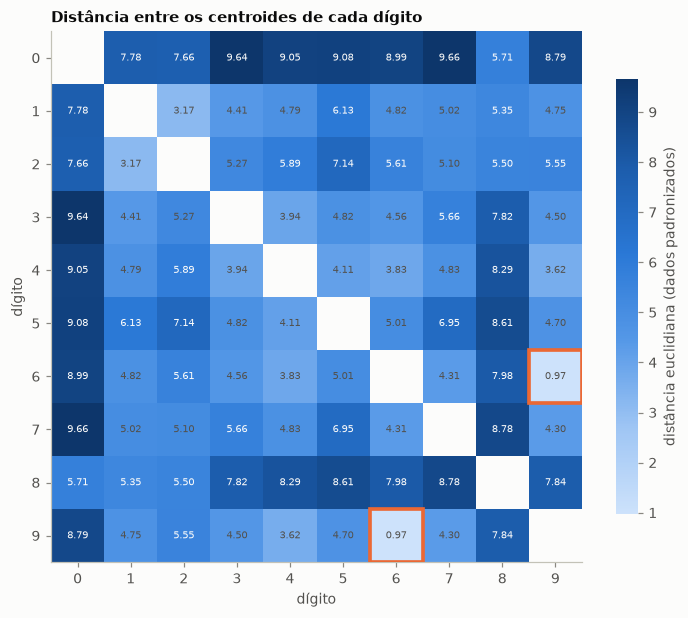

Pares de dígitos mais próximos:
  6 e 9: 0.97
  1 e 2: 3.17
  4 e 9: 3.62
  4 e 6: 3.83


In [25]:
from scipy.spatial.distance import pdist, squareform

# Centroide da classe k: o vetor médio das suas 200 instâncias — um ponto em R^76,
# o "espectro de forma médio" daquele dígito. Colapsa 200 pontos em 1.
centroides = np.array([Z[yv == k].mean(axis=0) for k in range(10)])
D = squareform(pdist(centroides))

fig, ax = plt.subplots(figsize=(6.8, 5.6))
Dm = D.copy()
np.fill_diagonal(Dm, np.nan)
cmap = RAMPA_SEQ.copy()
cmap.set_bad(SURFACE)
im = ax.imshow(Dm, cmap=cmap)  # sequencial: um matiz, claro -> escuro (magnitude)

for i in range(10):
    for j in range(10):
        if i == j:
            continue
        v = D[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.8,
                color=SURFACE if v > np.nanmax(Dm) * 0.55 else INK2)

# O par 6-9 é o achado: destacado por moldura, não por cor — a cor já codifica magnitude.
for (i, j) in [(6, 9), (9, 6)]:
    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False,
                               edgecolor=LARANJA, linewidth=2.4, zorder=5))

ax.set_title("Distância entre os centroides de cada dígito", loc="left",
             fontsize=10, weight="bold")
ax.set(xticks=range(10), yticks=range(10), xlabel="dígito", ylabel="dígito")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.82)
cb.set_label("distância euclidiana (dados padronizados)", color=INK2)
cb.outline.set_visible(False)

plt.tight_layout()
plt.show()

pares = sorted((D[i, j], i, j) for i in range(10) for j in range(i + 1, 10))
print("Pares de dígitos mais próximos:")
for d, i, j in pares[:4]:
    print(f"  {i} e {j}: {d:.2f}")

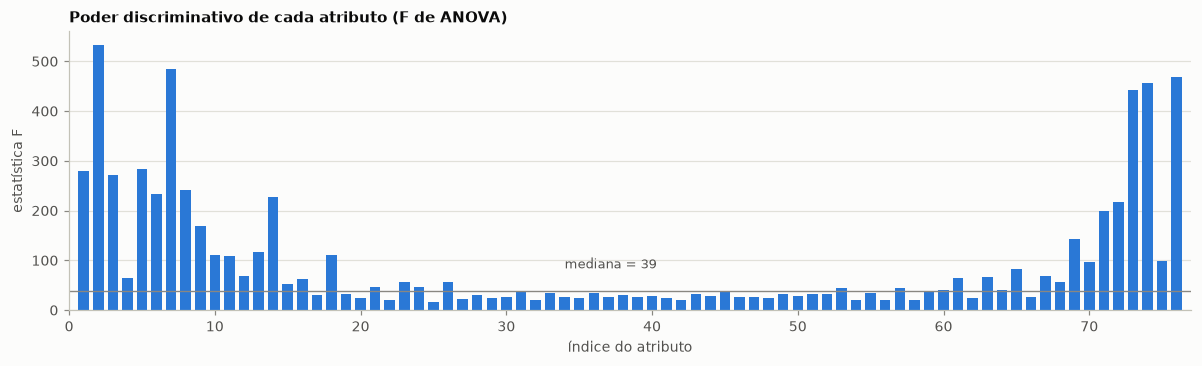

F por atributo: mín 16 | mediana 39 | máx 533
F médio por faixa de índice:
  att 1-19:   183
  att20-38:    32
  att39-57:    30
  att58-76:   139

10 atributos mais discriminativos: ['att2', 'att7', 'att76', 'att74', 'att73', 'att5', 'att1', 'att3', 'att8', 'att6']

Teste do pareamento espelhado (i, 77-i): |corr| média 0.143 vs 0.146 da linha de base -> sem evidência


In [26]:
from sklearn.feature_selection import f_classif

F_score, _ = f_classif(X.to_numpy(), yv)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(1, n_attr + 1), F_score, color=AZUL, width=0.72)
ax.axhline(np.median(F_score), color=MUTED, linewidth=0.9, zorder=1)
ax.annotate(f"mediana = {np.median(F_score):.0f}", xy=(38, np.median(F_score)),
            xytext=(34, np.median(F_score) + 45), fontsize=8.5, color=INK2)
ax.set_title("Poder discriminativo de cada atributo (F de ANOVA)",
             loc="left", fontsize=10, weight="bold")
ax.set(xlabel="índice do atributo", ylabel="estatística F", xlim=(0, n_attr + 1))
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"F por atributo: mín {F_score.min():.0f} | mediana {np.median(F_score):.0f} "
      f"| máx {F_score.max():.0f}")
print("F médio por faixa de índice:")
for lo, hi in [(0, 19), (19, 38), (38, 57), (57, 76)]:
    print(f"  att{lo + 1:2d}-{hi:2d}: {F_score[lo:hi].mean():5.0f}")
print(f"\n10 atributos mais discriminativos: "
      f"{[f'att{i + 1}' for i in np.argsort(F_score)[::-1][:10]]}")

# Teste da conjectura de que os extremos seriam pares +k/-k de um mesmo harmônico.
espelho = [Corr[i, n_attr - 1 - i] for i in range(n_attr // 2)]
print(f"\nTeste do pareamento espelhado (i, {n_attr + 1}-i): "
      f"|corr| média {np.mean(np.abs(espelho)):.3f} "
      f"vs {np.abs(fora_diag).mean():.3f} da linha de base -> sem evidência")

### Síntese da análise exploratória

| Achado | Evidência | Consequência |
|---|---|---|
| Balanceamento perfeito, sem faltantes | 200 por classe; 0 faltantes | acurácia é métrica honesta; sem imputação |
| Sem problema de outliers | 1% das células (taxa esperada); só 2 instâncias com ≥10 | não remover; justificar |
| Assimetria branda | mediana 0,55; 1 de 76 acima de 1 | **não** transformar (log/Box-Cox) |
| Escalas desiguais | razão de desvios 4,7× | padronizar, dentro do `Pipeline` |
| **Sem redundância _linear_** | \|corr\| média 0,146; máx 0,679; nenhum par > 0,8 | Pearson sozinho não decide a questão |
| **Redundância não linear, grande** | dCor acima do nulo em 1470 de 2850 pares; relações em arco | Pearson e PCA são cegos a ela |
| **Variedade curva de ~11 dimensões** | TwoNN 10,8 vs 32,0 no controle gaussiano, com estimador calibrado | a lacuna para os 58 do PCA é a curvatura |
| **Curvatura não explorável** | kPCA não supera o PCA; SVM-RBF ganha 1,2 pt, dentro do desvio | teto ~83%, imposto pela representação |
| **PCA pouco compressivo** | 58 de 76 componentes para 95% | `n_components` é hiperparâmetro, não escolha *a priori* |
| Contribuição desigual dos atributos | perfil em U; metade com F ≈ 30 | seleção de atributos como alternativa ao PCA |
| **Classes fortemente sobrepostas** | silhouette 0,038 com rótulos verdadeiros | a dificuldade do conjunto está aqui |
| **6 e 9 quase coincidentes** | centroides a 0,97 — 1º de 45, 3,3× à frente do 2º; fundidos em LDA e t-SNE | limitação da *representação*; teto de desempenho |

A conclusão que orienta o restante do trabalho é que este conjunto **não tem problemas de qualidade
de dados a corrigir**. Sua dificuldade é estrutural: as classes se sobrepõem no espaço de atributos,
e um par específico — 6 e 9 — é praticamente indistinguível por construção da representação de
Fourier. Isso estabelece um teto para qualquer classificador e desloca o interesse do trabalho de
"qual modelo acerta mais" para "o que, exatamente, limita todos eles".

## **Pré-processamentos**

#### Duplicatas exatas: remover

A análise exploratória encontrou 6 pares de linhas idênticas nos 76 atributos, todos com rótulos concordantes — não há ruído de rótulo, mas há redundância de amostra. Mantê-las arriscaria que o mesmo padrão apareça simultaneamente no treino e na validação de algum fold da validação cruzada (vazamento leve, que infla artificialmente as métricas de desempenho). Como a perda é mínima (6 de 2000, distribuída entre poucas classes) e o conjunto continua praticamente balanceado depois da remoção, optamos por removê-las antes de qualquer divisão em folds.

In [ ]:
n_antes = len(df)
df = df.drop_duplicates(subset=FEATURES).reset_index(drop=True)

X = df[FEATURES].astype(np.float64)
y = df["digit"]
yv = y.to_numpy()
n_inst = len(df)

print(f"Instâncias antes da remoção de duplicatas .. {n_antes}")
print(f"Instâncias após a remoção .................. {n_inst} ({n_antes - n_inst} removidas)")
print("\nInstâncias por dígito após a remoção:")
print(y.value_counts().sort_index().to_string())

#### Divisão dos dados: validação cruzada aninhada, sem conjunto de teste separado

Com apenas 200 instâncias por dígito (199-200 após a remoção de duplicatas), reservar um conjunto de teste fixo (por exemplo, 20%) deixaria cada classe com ~40 exemplos de teste, tornando a estimativa de erro por classe mais ruidosa — e ainda reduziria os dados disponíveis para treino e ajuste de hiperparâmetros.

Optamos por **validação cruzada aninhada**: um *outer loop* de 10 folds estratificados avalia o desempenho, e um *inner loop* (dentro do treino de cada fold do outer loop) faz a busca de hiperparâmetros, sem que o inner loop veja a parte reservada pelo outer loop. Repetindo por 10 folds, cada instância acaba sendo avaliada exatamente uma vez, por um modelo que não a viu em treino — o conjunto dessas previsões *out-of-fold* (via `cross_val_predict` com o mesmo esquema de folds) é o que usaremos tanto para as métricas de desempenho quanto para a análise de erros, mais à frente. Assim, 100% dos dados servem para treino e para avaliação, em camadas separadas, sem vazamento.

Como o arquivo original está ordenado em blocos contíguos por classe (visto na seção de contexto), `shuffle=True` com um `random_state` fixo é obrigatório, tanto para embaralhar as instâncias quanto para garantir reprodutibilidade.

In [ ]:
RANDOM_STATE = 0
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

print(f"outer_cv: {outer_cv.get_n_splits()} folds | shuffle={outer_cv.shuffle} | "
      f"random_state={outer_cv.random_state}")

#### Padronização e redução de dimensionalidade: dentro do `Pipeline`

A padronização (`StandardScaler`) é necessária pelo mesmo motivo discutido na seção de contexto: os desvios-padrão variam por um fator de ~4,7 entre atributos, o que distorce qualquer método baseado em distância ou gradiente. A diferença em relação ao uso feito durante a EDA é que, ali, o `StandardScaler` foi ajustado no conjunto inteiro só para fins exploratórios; a partir daqui ele entra como a **primeira etapa de um `Pipeline`**, ajustado apenas no treino de cada fold e aplicado (`transform`) na validação — evitando que estatísticas da parte de teste vazem para o treino.

A EDA também mostrou que a dimensionalidade intrínseca dos dados (~11, por TwoNN/MLE) é bem menor que os 76 atributos originais, mas que essa curvatura **não se mostrou explorável**: o kernel PCA não reconstruiu melhor que o PCA linear, e o ganho de modelos não lineares foi pequeno. Por isso, a redução de dimensionalidade (PCA) não é aplicada incondicionalmente — ela entra como **uma etapa opcional do `Pipeline`**, com `n_components` (incluindo a opção de não reduzir, `passthrough`) tratado como hiperparâmetro a ser testado empiricamente na seleção aninhada da próxima seção.

In [ ]:
from sklearn.pipeline import Pipeline

pipeline_exemplo = Pipeline([
    ("scaler", StandardScaler()),
    ("reduce_dim", "passthrough"),  # ou PCA(n_components=k) — a escolha final é feita na próxima seção
    ("clf", LogisticRegression(max_iter=3000)),
])

opcoes = [("sem redução", "passthrough"),
          ("PCA (k=33, ~80% var.)", PCA(n_components=33, random_state=0))]

print("Demonstração do padrão de Pipeline (StandardScaler + redução opcional + classificador):")
for nome, reduce_dim in opcoes:
    pipeline_exemplo.set_params(reduce_dim=reduce_dim)
    s = cross_val_score(pipeline_exemplo, X.to_numpy(), yv, cv=outer_cv, n_jobs=-1)
    print(f"  {nome:24s} {s.mean():.3f} ± {s.std():.3f}")

#### O que não é necessário, e por quê

A EDA já havia adiantado essas conclusões; aqui elas são reunidas como decisões explícitas de pré-processamento:

- **Imputação**: não há valores faltantes (0 em 152 000 células) — não há o que imputar.
- **Codificação do alvo**: `digit` já é numérico (0–9); não há necessidade de `LabelEncoder`/one-hot.
- **Codificação de atributos**: os 76 atributos são todos contínuos (`float64`); não há variáveis categóricas.
- **Rebalanceamento de classes**: o conjunto é (quase) perfeitamente balanceado mesmo após a remoção de duplicatas; `SMOTE`, subamostragem ou pesos de classe não se justificam. A estratificação do `outer_cv` já garante que cada fold preserve essa proporção.
- **Transformação de assimetria (log/Box-Cox)**: assimetria mediana de 0,55, com apenas 1 dos 76 atributos acima de 1 — não há assimetria severa a corrigir.
- **Remoção de outliers**: ~1% das células sinalizadas pelo critério de 1,5·IQR, consistente com a taxa esperada ao acaso para 76 atributos — não há padrão anômalo, e remover essas observações descartaria variação legítima.

### Síntese do pré-processamento

| Etapa | Aplicada? | Onde/como | Justificativa |
|---|---|---|---|
| Remoção de duplicatas exatas | Sim | uma vez, antes da divisão em folds | evita vazamento entre treino e validação |
| Embaralhamento + estratificação | Sim | `StratifiedKFold(shuffle=True, random_state=0)` | arquivo ordenado por classe; preserva balanceamento em cada fold |
| Padronização (`StandardScaler`) | Sim | primeira etapa do `Pipeline`, ajustada por fold | escalas desiguais (fator ~4,7) distorcem métodos por distância/gradiente |
| Redução de dimensionalidade (PCA) | Opcional/testável | etapa do `Pipeline`, `n_components` como hiperparâmetro | dimensão intrínseca ~11, mas curvatura não comprovadamente explorável |
| Imputação | Não | — | 0 valores faltantes |
| Codificação (alvo/atributos) | Não | — | alvo já numérico; atributos já contínuos |
| Rebalanceamento de classes | Não | — | conjunto (quase) perfeitamente balanceado |
| Transformação de assimetria | Não | — | assimetria branda (mediana 0,55) |
| Remoção de outliers | Não | — | taxa de outliers condizente com o esperado ao acaso |
| Divisão dos dados | CV aninhada, sem holdout | `outer_cv` (10 folds) + busca de hiperparâmetros no inner loop | amostra pequena por classe; aproveita 100% dos dados com previsões out-of-fold para a análise de erros |

Com essas decisões fixadas, a próxima seção aplica o pipeline de aprendizado de máquina propriamente dito, testando diferentes classificadores e hiperparâmetros dentro do esquema de validação cruzada aninhada definido aqui.

## **Aplicando o pipeline de AM**

Aplique as técnicas de AM segundo o pipeline recomendado com 10-fold cross-validation e seleção aninhada de hiperparâmetros. Apresente resultados de média e desvio-padrão de métricas de desempenho que julgue adequadas para seu conjunto de dados. Discuta os resultados: que técnica foi melhor? os resultados foram estáveis? etc.

## **Analisando os erros**

Aqui focaremos em analisar onde as técnicas estão errando e tentar entender por que esses erros estão ocorrendo. Todo mundo erra a mesma coisa? Que características têm as instâncias em que os maiores erros são cometidos? Faça discussões.

## **Conclusões**

Quais são suas conclusões sobre os experimentos realizados? Resuma o que foi alcançado no trabalho e tente propor estratégias para trabalhos futuros com esses dados. Agradeço também se puderem dar um feedback sobre o que acharam do trabalho. E declarem explicitamente o uso de ferramentas de LLM para auxílio ao desenvolvimento do trabalho.

## **Referências**

Inclua aqui as referências que tiver consultado/usado